In [1]:
# -- uncomment to get interactive plots
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pmoired

# -- in case you want to limit the number of cores for the multiprocessing functions
# -- will take all CPUs otherwise! 
pmoired.MAX_THREADS = 6 
print('will use', pmoired.MAX_THREADS, 'CPUs for multiprocessing')

will use 6 CPUs for multiprocessing


-- Please aknowledge the use of PMOIRED -----------
https://github.com/amerand/PMOIRED#using-and-quoting-pmoired
--------------------------------------------------- 
loadOI: loading MIRC_L2.2014Jul31.GL_586A.MIRCX_IDL.JDM.SPLIT.oifits
  > insname: "H_PRISM" targname: "GL_586A" pipeline: "" calibrated: unknown
  > MJD: (100,) [56869.1828..56869.2304] ~2014-07-31T04:52:57.514
  > E2-S2-W1-W2 | WL: (8,) [ 1.493 .. 1.725 ] um (R~55 P~50) {'T3': 4, 'VIS': 6, 'VIS2': 6} | TELL: False 


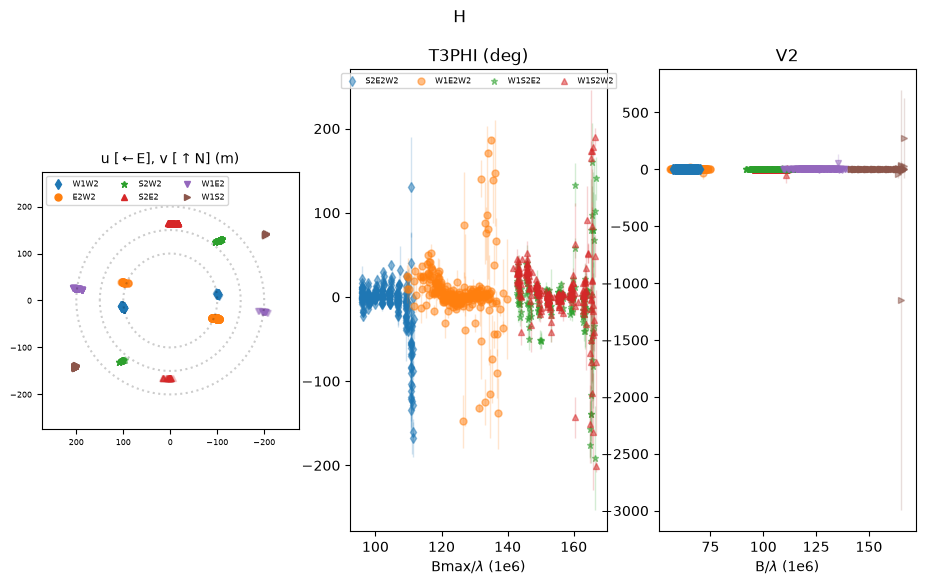

In [2]:
oi = pmoired.OI('MIRC_L2.2014Jul31.GL_586A.MIRCX_IDL.JDM.SPLIT.oifits') #binning=3)
oi.show(obs=['V2', 'T3PHI'])

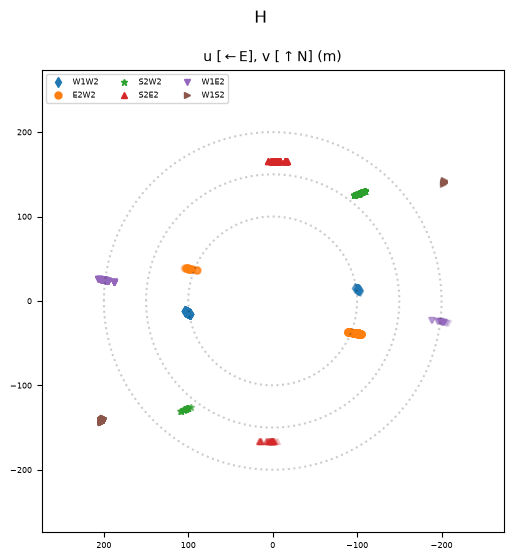

In [3]:
oi.show(obs=['']) # Show u, v only
# oi.show(obs=['V2']) 

In [4]:
plx = 51.1421 # mas from Gaia
R1 = 0.92 # From Strassmeier et al. 2013
R2 = 0.59 # From Strassmeier et al. 2013
R_Solar = 6.957e+8 # solar radii in meters
d_pc = 3.086e16 # pc in meters

data = oi.data[0]
print(data.keys())
print('\n')
print(f'Instrument: {data['insname']}')
print(f'Telescopes: {data['telescopes']}')
print(f'Baselines: {data['baselines']}')
print(f'Triangles: {data['triangles']}')
print('Mean MJD:', np.mean(data['MJD']))
print('Duration of Observation (min)', 24*60*(np.max(data['MJD']) - np.min(data['MJD'])))

dict_keys(['insname', 'filename', 'targname', 'pipeline', 'LST', 'header', 'calibrated', 'WL', 'dWL', 'OI_VIS2', 'OI_VIS', 'OI_T3', 'units', 'telescopes', 'baselines', 'triangles', 'TELLURICS', 'configurations per MJD', 'MJD', 'recipes'])


Instrument: H_PRISM
Telescopes: ['E2', 'S2', 'W1', 'W2']
Baselines: ['E2W2', 'S2E2', 'S2W2', 'W1E2', 'W1S2', 'W1W2']
Triangles: ['S2E2W2', 'W1E2W2', 'W1S2E2', 'W1S2W2']
Mean MJD: 56869.20344344852
Duration of Observation (min) 68.5416987980716


In [5]:
wl = data['WL']
d_wl = data['dWL']
print(f'Lambda (um)', wl)
print('Delta Lambda (um)', d_wl)
print('Spectral Resolution R', wl/d_wl)


wl_min = np.min(wl)
wl_max = np.max(wl)
wl_mean = np.mean(wl)
R_mean = np.mean(wl/d_wl)
print('Mean Wavelength (um):',wl_mean)
print('Mean R:', R_mean)


Lambda (um) [1.49289519 1.51470965 1.55155715 1.58774697 1.62327922 1.65815391
 1.69237103 1.72545015]
Delta Lambda (um) [0.01429788 0.02933098 0.03651866 0.03586104 0.03520347 0.03454591
 0.03364812 0.03251012]
Spectral Resolution R [104.41373032  51.64197784  42.48669843  44.27498993  46.11134076
  47.99856517  50.29615301  53.07425462]
Mean Wavelength (um): 1.6057704073091372
Mean R: 55.03721376143902


In [6]:
# Get min and max baseline lengths for each baseline

data = oi.data[0]

baseline_lengths = {}                
for b in data['baselines']:
    v = data['OI_VIS2'][b]
    baseline_lengths[b] = np.hypot(v['u'], v['v'])   
    #print(b, np.round(baseline_lengths[b], 2))


max_baselines = []
min_baselines = []
print("Baseline, Min (m), Max (m)")
for b in data['baselines']:
    print(b, baseline_lengths[b].min(), baseline_lengths[b].max())
    max_baselines.append(baseline_lengths[b].max())
    min_baselines.append(baseline_lengths[b].min())
    # usually go to 1/4 * lamda/longest baseline


# MAXIMUM BASELINE LENGTHS (in meters) FOR EACH BASELINE:
# BASELINE: W1S2; 247.98848075397257 m
# WAVELENGTH: 1.587e-06 m

Bmax = np.max(max_baselines) # meters
Bmin = np.min(min_baselines) # meters
wavelength = wl_mean / 1e6 # meters
fineness_factor = 1/4
max_resolution = fineness_factor * (wavelength / Bmax) * 206265e3 # in mas, 0.329997742239 mas
print('Max Baseline', Bmax, 'm')
print('Min Baseline', Bmin, 'm')
print('Fringe Spacing', (wavelength / Bmax) * 206265e3, 'mas')
print(f'Maximum Resolution for Search', max_resolution, "mas")

Baseline, Min (m), Max (m)
E2W2 96.68114286529436 111.66415817697028
S2E2 165.47427381899848 166.4464474030943
S2W2 158.2367117991325 170.35952233075432
W1E2 188.78578020827547 208.7376110793397
W1S2 244.26117607425837 248.725809310474
W1W2 98.73648979380738 104.50517960603615
Max Baseline 248.725809310474 m
Min Baseline 96.68114286529436 m
Fringe Spacing 1.3316440058304457 mas
Maximum Resolution for Search 0.33291100145761143 mas


In [7]:
# Angular Diameter Calculation

theta_ud1 = 206265e3 * ((2 * R1 * R_Solar) / ((1/(plx*1e-3)) * d_pc))
theta_ud2 = 206265e3 * ((2 * R2 * R_Solar) / ((1/(plx*1e-3)) * d_pc))
print('UD1:',theta_ud1)
print('UD2:',theta_ud2)

UD1: 0.43757046743171013
UD2: 0.2806158432442489


setupFit> 0/H_PRISM: setting 'wl kernel':0.9 according to WL definition
1920 grid points not within constraints
Tue Nov  3 13:40:36 2026: running 6361 fits on 10 processes
Tue Nov  3 13:48:50 2026: [████████████████████████████████████████████████████████████]6361/6361   0s   left

Tue Nov  3 13:48:50 2026: it took 494.0s, 0.08s per fit on average [772.5 fit/minute]
fits to be taken into account: 6356 / 6361
  5 have uncertainties larger than the grid's step[s]
Tue Nov  3 13:48:50 2026: making list of unique minima...
Tue Nov  3 13:49:21 2026: [████████████████████████████████████████████████████████████]6356/6356   0s   left

unique minima: 899 / 6356 [~7.1 first guesses / minima]
  few unique minima -> grid too fine / Nfits too large?
Tue Nov  3 13:49:21 2026: linking unique minima to first guess(es)
Tue Nov  3 13:49:21 2026: done
------------
best fit: chi2= 6.3123021280169445
{'B,f': 0.2605, # +/- 0.0061
'B,x': -11.9068, # +/- 0.0055
'B,y': 3.766, # +/- 0.010
'A,f': 1.0,
'A,ud':0.4

/Users/ethanchen/ASTRO2/ASTRO399/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


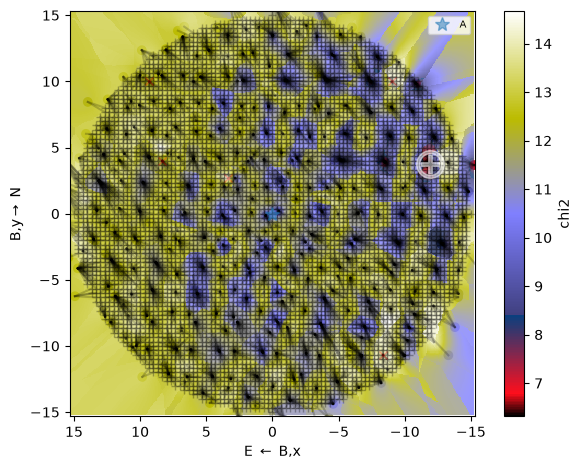

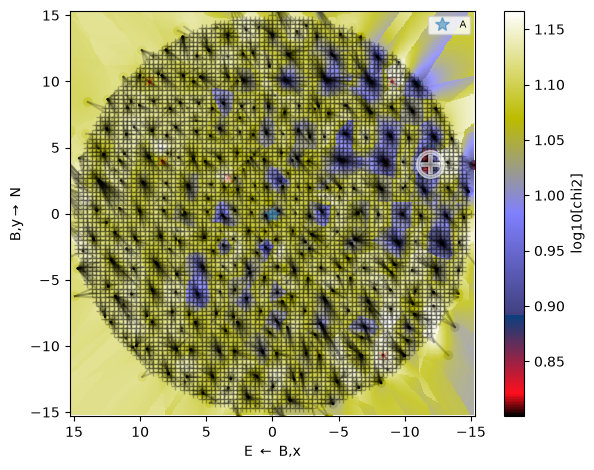

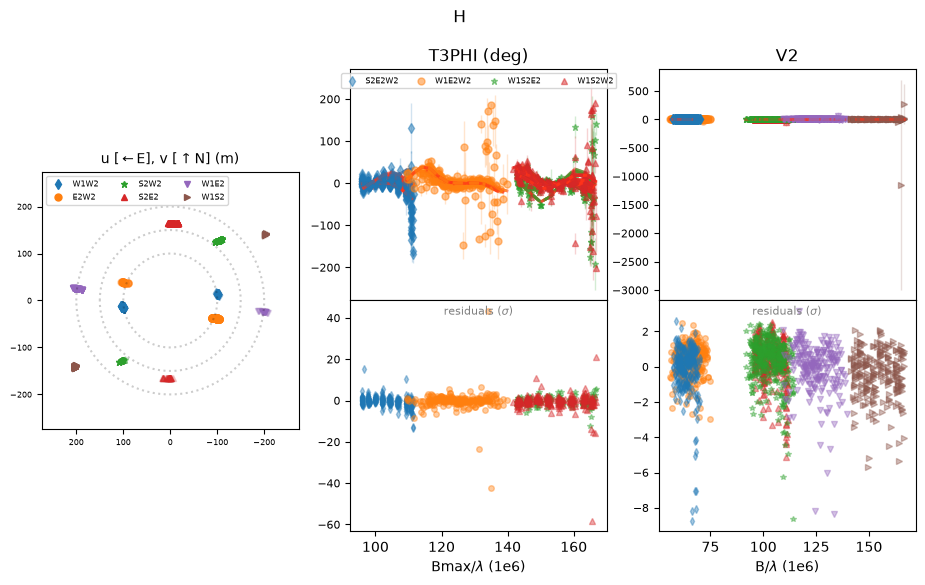

In [8]:
# Define model
# A at the origin, B offset (x East, y North, in mas)

maxsep1 = 15.0
step1 = max_resolution  

param = {
    'A,f': 1.0,
    'A,ud': theta_ud1,      
    'A,x': 0.0, 'A,y': 0.0,
    'B,f': 0.2362529748,         # flux relative to A, initial guess at 2014-08-02 fit
    'B,ud': theta_ud2,      
    'B,x': 0.0, 'B,y': 0.0,
}

# Flux of B must be lower than A component
prior = [('B,f', '<', 1)]

# Constraints on B's position
# - Separation must be less than the maximum separation
constrain = [( 'np.sqrt(B,x**2+B,y**2)', '<', maxsep1)]


# parameters that will be fixed and not fitted
fixed = ['A,f', 'A,ud', 'A,x', 'A,y', 'B,ud'] # Fix B,f for bad fits


oi.setupFit({'obs': ['V2', 'T3PHI'], 'min relative error': {'V2': 0.01}})


# Grid search over B's position
expl = {'grid': {'B,x': (-maxsep1, maxsep1, step1), 'B,y': (-maxsep1, maxsep1, step1)}}
oi.gridFit(expl, model=param, doNotFit=fixed, constrain=constrain, prior=prior)

# -- show the grid result
oi.showGrid()

# -- show the log grid result
oi.showGrid(interpolate=True, logV=1)

# -- show the data and the best fit model
oi.show()

In [9]:
# list the distinct minima it found in the unzoomed, best first
rows1 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows1.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows1.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows1[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

-----------------------------------------
  chi2r    sep(mas)   PA(deg)   f_B/f_A
6.3123021280169445  12.488145520478295  287.5516853960076  0.26051246876529316
6.402920585499225  12.439539354287893  287.7896865526288  0.25382991131004184
6.444262012759612  12.43054592799545  287.8556335578964  0.2475707431265032
6.7241419767933  9.35290517726044  294.6641402427727  0.3011625434748263
7.098318584890295  15.67737092134899  283.5525384154387  0.2135787055074898
7.690676095663504  14.661706791119995  312.26680529123337  0.2098637298420753
7.7379037814190985  12.453576820551936  323.56433943431017  0.23130055961745535
8.067217451986325  13.067674665008298  259.89491054373275  0.24033712059206294


In [11]:
# The best fit position of component B, not zoomed in
x1 = oi.bestfit['best']['B,x']
y1 = oi.bestfit['best']['B,y']
pa1 = np.degrees(np.arctan2(x1, y1)) % 360
print(f'{x1}, {y1} mas, PA = {pa1} deg')

-11.906763676611119, 3.766000171266081 mas, PA = 287.5516853960076 deg


In [ ]:
# Refine the fit around the best fit point (x1, y1)

maxsep2 = 10
step2 = max_resolution        # half-width and step, in mas

expl = {'grid': {'B,x': (x1-maxsep2, x1+maxsep2, step2),
                 'B,y': (y1-maxsep2, y1+maxsep2, step2)}}

oi.gridFit(expl, model=oi.bestfit['best'], doNotFit=fixed, prior=prior)   # no constrain
oi.showGrid()
oi.showGrid(interpolate=True, logV=1)
oi.show()

In [ ]:
# list the distinct minima it found in the zoomed, best first
rows2 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows2.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows2.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows2[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

In [ ]:
# The best fit position of component B, zoomed in
x2 = oi.bestfit['best']['B,x']
y2 = oi.bestfit['best']['B,y']
pa2 = np.degrees(np.arctan2(x2, y2)) % 360
print(f'{x2}, {y2} mas, PA = {pa2} deg')

In [ ]:
# Refine the fit around the best fit point

x3 = x2
y3 = y2
maxsep3 = 1
step3 = 0.02        # half-width and step, in mas

expl = {'grid': {'B,x': (x2-maxsep3, x2+maxsep3, step3),
                 'B,y': (y2-maxsep3, y2+maxsep3, step3)}}

oi.gridFit(expl, model=oi.bestfit['best'], doNotFit=fixed, prior=prior)   # no constrain
oi.showGrid()
oi.showGrid(interpolate=True, logV=1)
oi.show()

In [ ]:
# list the distinct minima it found in the zoomed, best first
rows3 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows3.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows3.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows3[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

In [ ]:
# The best fit position of component B, zoomed in for a second time
x3 = oi.bestfit['best']['B,x']
y3 = oi.bestfit['best']['B,y']
pa3 = np.degrees(np.arctan2(x3, y3)) % 360
print(f'{x3}, {y3} mas, PA = {pa3} deg')

In [ ]:
# Refine Fit using the zoomed best fit, Bx_zoom, By_zoom
oi.doFit(oi.bestfit['best'], doNotFit=fixed)
oi.showFit()

In [ ]:
# Separation and position angle
b = oi.bestfit['best']
x, y = b['B,x'], b['B,y']
sep = np.hypot(x, y)
pa = np.degrees(np.arctan2(x, y)) % 360
print(f"sep = {sep} mas, PA = {pa} deg, f_B/f_A = {b['B,f']}")
print(x, y)

In [ ]:
# Uncertainties

oi.bootstrapFit(Nfits=500)
oi.showBootstrap()

In [ ]:
# BEST FIT PARAMETERS AND UNCERTAINTIES

# Separation and position angle
b = oi.bestfit['best']
x, y = b['B,x'], b['B,y']
sep = np.hypot(x, y)
pa = np.degrees(np.arctan2(x, y)) % 360
print(f"sep = {sep} mas, PA = {pa} deg, f_B/f_A = {b['B,f']}")
print(x, y)

In [ ]:
# Summary of all the Grid Fits

print(f"Grid Size: {2*maxsep1} x {2*maxsep1} mas; Step = {step1} mas")
print(f"    Bx: {x1} mas; By: {y1} mas; PA = {pa1} deg")
print(f"Grid Size: {2*maxsep2} x {2*maxsep2} mas; Step = {step2} mas")
print(f"    Bx: {x2} mas; By: {y2} mas; PA = {pa2} deg")
print(f"Grid Size: {2*maxsep3} x {2*maxsep3} mas; Step = {step3} mas")
print(f"    Bx: {x3} mas; By: {y3} mas; PA = {pa3} deg")

In [19]:
# More readable grids without the movement of the fits plotted
# The dofit model (not using grid fit and keeping Bx, By fixed) searches in an area centered around the best fit of the last gridfit model (x3, y3)


start = dict(oi.bestfit['best']) # includes x3, y3, B,f and the fixed params
start['B,x'] = x1
start['B,y'] = y1

x1_2, y1_2 = x1, y1

maxsep1_2 = 15
step1_2 = 0.5       # half-width and step, in mas

xs = np.arange(x1_2-maxsep1_2, x1_2+maxsep1_2+step1_2/2, step1_2)
ys = np.arange(y1_2-maxsep1_2, y1_2+maxsep1_2+step1_2/2, step1_2)
frozen = fixed + ['B,x', 'B,y'] # B,f is still fitted at each point

chi2 = np.zeros((len(ys), len(xs)))

progress = 0

for j, y in enumerate(ys):
    for i, x in enumerate(xs):
        p = dict(start); p['B,x'], p['B,y'] = x, y
        oi.doFit(p, doNotFit=frozen, prior=prior, verbose=0)
        chi2[j, i] = oi.bestfit['chi2']

    progress += len(xs)
    print(f'{progress}/{len(xs)*len(ys)}')

oi.doFit(start, doNotFit=fixed, verbose=0)   # restore oi.bestfit

61/3721
122/3721
183/3721
244/3721
305/3721
366/3721
427/3721
488/3721
549/3721
610/3721
671/3721
732/3721
793/3721
854/3721
915/3721
976/3721
1037/3721
1098/3721
1159/3721
1220/3721
1281/3721
1342/3721
1403/3721
1464/3721
1525/3721
1586/3721
1647/3721
1708/3721
1769/3721
1830/3721
1891/3721
1952/3721
2013/3721
2074/3721
2135/3721
2196/3721
2257/3721
2318/3721
2379/3721
2440/3721
2501/3721
2562/3721
2623/3721
2684/3721
2745/3721
2806/3721
2867/3721
2928/3721
2989/3721
3050/3721
3111/3721
3172/3721
3233/3721
3294/3721
3355/3721
3416/3721
3477/3721
3538/3721
3599/3721
3660/3721
3721/3721


NameError: name 'x3' is not defined

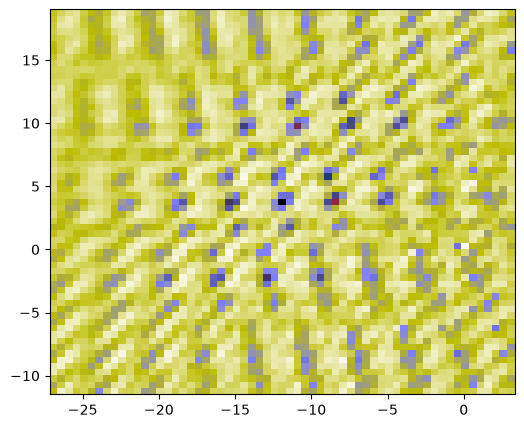

In [ ]:

plt.figure(figsize=(6, 5))

plt.pcolormesh(xs, ys, chi2, cmap='gist_stern')

plt.plot(x1, y1, marker='+', color='w', ms=14, mew = 1)


plt.colorbar(label='reduced chi2)')
plt.gca().invert_xaxis(); plt.gca().set_aspect('equal')
plt.xlabel('B,x (mas, E ←)'); plt.ylabel('B,y (mas, N →)')



In [ ]:
# Print the n grid points with the lowest chi2, with their B,x and B,y

n = 10                                           # how many to print

order = np.argsort(chi2, axis=None)              # flat indices, lowest chi2 first
order = order[np.isfinite(chi2.flat[order])]     # drop NaN (uncomputed) points

print(f'Top {min(n, len(order))} lowest chi2 grid points')
print('  rank    chi2r       B,x        B,y     sep(mas)   PA(deg)')
for rank, k in enumerate(order[:n], start=1):
    j, i = np.unravel_index(k, chi2.shape)       # row (y), column (x)
    x, y = xs[i], ys[j]
    print(f'{rank}  {chi2[j, i]}  {x}  {y}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}')

print('  rank    chi2r      sep(mas)   PA(deg)')
for rank, k in enumerate(order[:n], start=1):
    j, i = np.unravel_index(k, chi2.shape)       # row (y), column (x)
    x, y = xs[i], ys[j]
    print(f'{rank}  {chi2[j, i]} {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}')

In [ ]:
# To scale, based off calculated uds
disp = dict(oi.bestfit['best'])
oi.showModel(disp, imFov=1.2*maxsep1, imPix=0.1, imPow=0.5, showSED=False)

In [ ]:
# Not to scale
disp = dict(oi.bestfit['best'])
disp['A,ud'] = 5      # display size only, not measured
disp['B,ud'] = 4
oi.showModel(disp, imFov=0.5*maxsep1, imPix=0.6, imPow=1, showSED=False)